# Identity Resolution Matcher - Wikidata x OurAirports (Machine Learning)

### Purpose

Train and apply a machine-learning-based matcher between Wikidata and OurAirports airport records. The gold standard produced in `create_gold_standard.ipynb` (`gold_standard_wd_oa.csv`) is used as labeled training/validation/test data. Instead of the single hand-weighted similarity score used for ranking in the gold-standard notebook, a learned classifier combines multiple features into a match decision. The trained matcher is then applied to the full Wikidata x OurAirports candidate space to produce the final correspondences.

### Methods

1. **Load gold standard**: read `gold_standard_wd_oa.csv` and keep its existing `split` (train/val 70 % vs. test 30 %, held out until the final evaluation) and `fold` (5 stratified folds) columns.
2. **Feature engineering**: build similarity features per shared column (`name`, `city`, `countryName`, `countryCode`, `localCode`, `elevation`, `lat`/`lon`) using PyDI's `FeatureExtractor`. `icao`/`iata` stay out entirely - they are the identifiers used to build the gold standard's labels, so using them as features would leak the label.
3. **Model training & tuning**: train and tune four classifiers - Logistic Regression, SVM, Random Forest, XGBoost - with `GridSearchCV` over the existing `fold` column via `PredefinedSplit`, so every model is tuned and compared on the exact same 5 folds; standardize features for Logistic Regression/SVM, leave Random Forest/XGBoost unscaled.
4. **Evaluation**: compare the four models on the held-out test split (precision, recall, F1, ROC/PR curves, confusion matrix), with a separate breakdown by pair type.
5. **Error analysis**: inspect misclassified hard pairs to understand failure modes, mirroring the manual-inspection approach from the gold-standard notebook.
6. **Cluster analysis**: group the above-threshold pairs from step 7 into connected components (union-find) to detect conflicts - the same WD or OA record matched to more than one record on the other side. Each pair keeps its own score, tagged with its cluster id, and that tagged set is saved directly as the final correspondences; conflicts are left visible rather than resolved into a strict one-to-one set.
7. **Apply the matcher**: block the full Wikidata x OurAirports datasets (reusing the blocking rules from the gold-standard notebook), extract the same features for all candidate pairs, and score them with the best-performing model.
   - **Blocking key selection**: measure the blocking configuration actually used (Rule A union Rule B, deduplicated) against a full-scale ground-truth proxy built from ICAO/IATA matches, using Pair Completeness / recall = (positives still co-blocked) / (total positives) and Reduction Ratio = 1 - (candidate pairs) / (|WD| x |OA|). Target: recall > 97 %.


## 1. Load Gold Standard

Load the Wikidata and OurAirports normalized records (needed later for feature extraction, since the gold standard only stores `id1`/`id2`), and the labeled pairs from `create_gold_standard.ipynb`. The `split` column (`train_val` / `test`) and `fold` column (5 stratified folds within `train_val`) produced there are kept as-is: `test` is set aside untouched until the final evaluation, and `fold` is used for cross-validation during model training and tuning.

In [345]:
import pandas as pd
from pathlib import Path
from PyDI.io import load_csv

DATA_DIR = Path("../../../data/normalized_outputs")
GOLD_STANDARD_DIR = Path("../../../data/identity_resolution/gold_standard")

WIKIDATA_FILE = DATA_DIR / "wikidataNormalized.csv"
OURAIRPORT_FILE = DATA_DIR / "ourairportsNormalized.csv"
GOLD_STANDARD_FILE = GOLD_STANDARD_DIR / "gold_standard_wd_oa.csv"

df_wd = load_csv(WIKIDATA_FILE, name="wikidata")
df_wd.attrs["source"] = "wikidata"

df_oa = load_csv(OURAIRPORT_FILE, name="ourairports")
df_oa.attrs["source"] = "ourairports"

gold = pd.read_csv(GOLD_STANDARD_FILE)

print(f"Wikidata records: {len(df_wd):,}")
print(f"OurAirports records: {len(df_oa):,}")
print(f"Gold standard pairs: {len(gold):,}")
display(gold.head(3))

# test is held out untouched until the final evaluation (step 4)
train_val = gold[gold["split"] == "train_val"].copy()
test = gold[gold["split"] == "test"].copy()

print(f"\ntrain_val: {len(train_val):,} pairs, fold distribution:")
print(train_val["fold"].value_counts().sort_index())

print(f"\ntest (held out): {len(test):,} pairs")

print("\ntrain_val pairs by type:")
print(train_val["type"].value_counts())

Wikidata records: 24,859
OurAirports records: 86,151
Gold standard pairs: 1,210


,id1,id2,score,type,label,split,fold
0,wd_5221,oa_30703,0.289489,hard positive,1,train_val,1.0
1,wd_6251,oa_28495,0.306685,hard positive,1,train_val,1.0
2,wd_7518,oa_63370,0.340768,hard positive,1,train_val,0.0



train_val: 847 pairs, fold distribution:
fold
0.0    170
1.0    170
2.0    169
3.0    169
4.0    169
Name: count, dtype: int64

test (held out): 363 pairs

train_val pairs by type:
type
hard positive            175
normal positive          175
hard negative            175
normal negative          175
heliport negative         93
code changed positive     48
heliport positive          6
Name: count, dtype: int64


## 2. Feature Engineering

Build the comparator set used to turn each candidate pair into a feature vector. `icao` is excluded entirely (it is the identifier used to construct the gold standard's labels, so using it as a feature would leak the label). `iata` is left out for now as well. One cell per shared column states which similarity method(s) are used and why, then instantiates the comparators for that column.

### `name`

- Edit-based (char-level): `levenshtein`, `jaro`, `jaro_winkler`, `strcmp95`
- Token-based (word): `jaccard`, `sorensen_dice`, `overlap`, `cosine`
- Token-based (n-gram, tolerates typos the word-level tokenizer misses): `jaccard` (bigram), `cosine` (trigram)
- Containment: does one name fully contain the other (abbreviation / short-vs-long name, e.g. `wamba airport` vs. `kikongo sur wamba airport`)
- Monge-Elkan: for each word in one name, take its best (max) Jaro-Winkler match among the words in the other name, average, then average both directions. Catches reordered/partial name overlaps (e.g. "springfield international airport" vs. "international airport of springfield") that whole-string edit-based methods miss. PyDI's built-in `monge_elkan` option is not usable directly (it returns unnormalized scores), so this is a custom comparator.
- Extended (generalized) Jaccard on TF-IDF-weighted term vectors: `J(a, b) = (a . b) / (||a||^2 + ||b||^2 - a . b)`. Unlike the set-based `jaccard` above, this down-weights common tokens (e.g. "airport") via TF-IDF instead of treating every shared word equally, and is order-invariant like the set-based version.
- Soundex (phonetic, English-oriented) and Koelner Phonetik (phonetic, German-oriented): encode each word to a phonetic code, then take the Jaccard overlap of the code sets of the two names. Catches same-sounding, differently-spelled names. jellyfish provides `soundex`; Koelner Phonetik has no library implementation available here, so it is implemented from the standard rule table.

In [346]:
from PyDI.entitymatching import StringComparator, NumericComparator, BaseComparator
from PyDI.utils import SimilarityRegistry
import re
import jellyfish
from sklearn.feature_extraction.text import TfidfVectorizer


class ContainmentComparator(BaseComparator):
    """1.0 if one string is fully contained in the other (case-insensitive), else 0.0."""

    def __init__(self, column):
        super().__init__(name=f"ContainmentComparator({column})")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        a, b = v1.strip().lower(), v2.strip().lower()
        if not a or not b:
            return 0.0
        return 1.0 if (a in b or b in a) else 0.0




class MongeElkanComparator(BaseComparator):
    """Monge-Elkan similarity: for each token in one name, take the best (max) inner
    similarity to any token in the other name, average, then average both directions
    (symmetric). Uses Jaro-Winkler as the inner token similarity, so the result stays in [0, 1]."""

    def __init__(self, column="name", inner_similarity="jaro_winkler"):
        super().__init__(name=f"MongeElkanComparator({column})")
        self.column = column
        self._inner = SimilarityRegistry.get_function(inner_similarity, "char")

    def _tokens(self, value):
        return [t for t in str(value).strip().lower().split() if t]

    def _directional(self, tokens1, tokens2):
        return sum(max(self._inner(t1, t2) for t2 in tokens2) for t1 in tokens1) / len(tokens1)

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        tokens1, tokens2 = self._tokens(v1), self._tokens(v2)
        if not tokens1 or not tokens2:
            return 0.0
        return (self._directional(tokens1, tokens2) + self._directional(tokens2, tokens1)) / 2


_name_tfidf_vectorizer = TfidfVectorizer().fit(
    pd.concat([df_wd["name"], df_oa["name"]]).dropna().astype(str)
)


class ExtendedJaccardComparator(BaseComparator):
    """Generalized Jaccard on TF-IDF-weighted term vectors:
    J(a, b) = (a . b) / (||a||^2 + ||b||^2 - a . b)."""

    def __init__(self, column, vectorizer):
        super().__init__(name=f"ExtendedJaccardComparator({column})")
        self.column = column
        self.vectorizer = vectorizer

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        a, b = self.vectorizer.transform([v1, v2])
        dot = a.multiply(b).sum()
        denom = a.multiply(a).sum() + b.multiply(b).sum() - dot
        return float(dot / denom) if denom > 0 else 0.0


def koelner_phonetik(word):
    """Koelner Phonetik (Cologne phonetics): German phonetic code, standard rule table
    (see Wikipedia "Koelner Phonetik"). No ready-made implementation was available, so
    this follows the published letter-to-digit rules directly."""
    word = re.sub(r"[^A-ZÄÖÜß]", "", word.upper())
    if not word:
        return ""
    codes, n = [], len(word)
    for i, ch in enumerate(word):
        prev = word[i - 1] if i > 0 else ""
        nxt = word[i + 1] if i < n - 1 else ""
        if ch in "AEIJOUYÄÖÜ":
            codes.append("0")
        elif ch == "B":
            codes.append("1")
        elif ch == "P":
            codes.append("3" if nxt == "H" else "1")
        elif ch in "DT":
            codes.append("8" if nxt in "CSZ" else "2")
        elif ch in "FVW":
            codes.append("3")
        elif ch in "GKQ":
            codes.append("4")
        elif ch == "C":
            if i == 0:
                codes.append("4" if nxt in "AHKLOQRUX" else "8")
            elif prev in "SZ":
                codes.append("8")
            else:
                codes.append("4" if nxt in "AHKOQUX" else "8")
        elif ch == "X":
            codes.append("8" if prev in "CKQ" else "48")
        elif ch == "L":
            codes.append("5")
        elif ch in "MN":
            codes.append("6")
        elif ch == "R":
            codes.append("7")
        elif ch in "SZß":
            codes.append("8")
        else:
            codes.append("")
    raw = "".join(codes)
    if not raw:
        return ""
    collapsed = raw[0]
    for d in raw[1:]:
        if d != collapsed[-1]:
            collapsed += d
    return collapsed[0] + collapsed[1:].replace("0", "")


class PhoneticOverlapComparator(BaseComparator):
    """Jaccard overlap between the sets of per-word phonetic codes of the two names."""

    def __init__(self, column, phonetic_fn, fn_name):
        super().__init__(name=f"PhoneticOverlapComparator({column}, {fn_name})")
        self.column = column
        self.phonetic_fn = phonetic_fn

    def _codes(self, value):
        codes = set()
        for token in str(value).split():
            code = self.phonetic_fn(token)
            if code:
                codes.add(code)
        return codes

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        c1, c2 = self._codes(v1), self._codes(v2)
        if not c1 or not c2:
            return 0.0
        return len(c1 & c2) / len(c1 | c2)


name_comparators = [
    # edit-based (char-level)
    StringComparator(column="name", similarity_function="levenshtein"),
    StringComparator(column="name", similarity_function="jaro"),
    StringComparator(column="name", similarity_function="jaro_winkler"),
    StringComparator(column="name", similarity_function="strcmp95"),
    # token-based (word)
    StringComparator(column="name", similarity_function="jaccard", tokenization="word"),
    StringComparator(column="name", similarity_function="sorensen_dice", tokenization="word"),
    StringComparator(column="name", similarity_function="overlap", tokenization="word"),
    StringComparator(column="name", similarity_function="cosine", tokenization="word"),
    # token-based (n-gram)
    StringComparator(column="name", similarity_function="jaccard", tokenization="ngram_2"),
    StringComparator(column="name", similarity_function="cosine", tokenization="ngram_3"),
    # containment
    ContainmentComparator(column="name"),
    MongeElkanComparator(column="name"),
    ExtendedJaccardComparator(column="name", vectorizer=_name_tfidf_vectorizer),
    PhoneticOverlapComparator(column="name", phonetic_fn=jellyfish.soundex, fn_name="soundex"),
    PhoneticOverlapComparator(column="name", phonetic_fn=koelner_phonetik, fn_name="koelner_phonetik"),
]

print(f"{len(name_comparators)} comparators for `name`")

15 comparators for `name`


### `name` (embedding similarity)

Sentence-embedding cosine similarity on `name`, using PyDI's `VectorFeatureExtractor` (sentence-transformers under the hood). This is not a `BaseComparator`, so it is not part of `name_comparators` / `comparators` above - it produces its own feature column(s) directly from `df_left`/`df_right`/pairs, to be concatenated with the comparator-based features when the feature matrix is built.

**Deferred**: instantiating `SentenceTransformer` downloads model weights on first use (no cached model found in this environment), so this cell is written but not run yet - run it once network access / the cached model is available.

In [347]:
from PyDI.entitymatching import VectorFeatureExtractor

name_embedding_extractor = VectorFeatureExtractor(
    embedding_model="all-MiniLM-L6-v2",
    columns=["name"],
    distance_metrics=["cosine"],
)

print(name_embedding_extractor.model_name)

all-MiniLM-L6-v2


### `city`

- `jaro_winkler` (reused from the ranking score in `create_gold_standard.ipynb`)
- Exact match flag

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [348]:
class ExactMatchComparator(BaseComparator):
    """1.0 if both values are non-null and equal (case-insensitive, trimmed), else 0.0."""

    def __init__(self, column):
        super().__init__(name=f"ExactMatchComparator({column})")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        return 1.0 if v1.strip().lower() == v2.strip().lower() else 0.0


city_comparators = [
    StringComparator(column="city", similarity_function="jaro_winkler"),
    ExactMatchComparator(column="city"),
]

print(f"{len(city_comparators)} comparators for `city`")


2 comparators for `city`


### `countryName`

- `jaro_winkler` (spelling/translation variants)
- Exact match flag (backup signal for when `countryCode` is missing on one side)

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [349]:
countryname_comparators = [
    StringComparator(column="countryName", similarity_function="jaro_winkler"),
    ExactMatchComparator(column="countryName"),
]

print(f"{len(countryname_comparators)} comparators for `countryName`")


2 comparators for `countryName`


### `countryCode`

- Exact match flag only (fixed-length code, edit distance is not meaningful here)

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [350]:
countrycode_comparators = [
    ExactMatchComparator(column="countryCode"),
]

print(f"{len(countrycode_comparators)} comparators for `countryCode`")


1 comparators for `countryCode`


### `localCode`

- `levenshtein` (format/typo differences between sources)
- Exact match flag

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [351]:
localcode_comparators = [
    StringComparator(column="localCode", similarity_function="levenshtein"),
    ExactMatchComparator(column="localCode"),
]

print(f"{len(localcode_comparators)} comparators for `localCode`")


2 comparators for `localCode`


### `elevation`

- `sim_num_abs` (`NumericComparator`, `absolute_difference`, in meters): the same airport should report nearly the same elevation, so this helps rule out pairs that merely share a similar name but sit in different places.
- `sim_num_perc` (`NumericComparator`, `relative_difference`, Winter-compatible percentage similarity): complements the absolute version for airports at very different base elevations, where the same absolute gap means something different (e.g. 50 m off at sea level vs. 50 m off at 4000 m).

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [352]:
elevation_comparators = [
    NumericComparator(column="elevation", method="absolute_difference", max_difference=100.0),
    NumericComparator(column="elevation", method="relative_difference", max_difference=0.5),
]

print(f"{len(elevation_comparators)} comparators for `elevation`")


2 comparators for `elevation`


### `lat` / `lon`

- `distance_km`: raw, unbounded Haversine distance in km - no `max_distance_km` cutoff, so the models learn their own distance thresholds instead of a fixed one. Several hard-positive false negatives we found were 2-29 km apart (same airport, noisy coordinates); a bounded similarity would floor all of them to the same value. Missing coordinates fall back to a constant (2.0 km).
- Missing-coordinate flag: `coordinate_missing` tells the model when the fallback distance was used, instead of it being a genuinely short distance.


In [353]:
import math


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance between two lat/lon points, in km."""
    R = 6371.0  # Earth radius in km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))


class DistanceKmComparator(BaseComparator):
    """Raw great-circle distance in km, unbounded - no max_distance_km cutoff, so the
    models learn their own distance thresholds instead of a fixed one. Missing
    coordinates fall back to a constant; coordinate_missing distinguishes this from a
    genuine short distance."""

    def __init__(self, lat_column="lat", lon_column="lon", missing_fallback_km=2.0):
        super().__init__(name="distance_km")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.missing_fallback_km = missing_fallback_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return self.missing_fallback_km
        return haversine_km(lat1, lon1, lat2, lon2)


class CoordinateMissingComparator(BaseComparator):
    """1.0 if either record is missing lat/lon, else 0.0."""

    def __init__(self, lat_column="lat", lon_column="lon"):
        super().__init__(name="coordinate_missing")
        self.lat_column = lat_column
        self.lon_column = lon_column

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        return 1.0 if (pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2)) else 0.0


geo_comparators = [
    DistanceKmComparator(missing_fallback_km=2.0),
    CoordinateMissingComparator(),
]

print(f"{len(geo_comparators)} comparators for `lat`/`lon`")


2 comparators for `lat`/`lon`


### Combine

Collect every column's comparators into one list. `iata` and `icao` stay out for now; `iata`'s missing-value pattern and TF-IDF-weighted name similarity are deferred (see discussion).

In [354]:
comparators = (
    name_comparators
    + city_comparators
    + countryname_comparators
    + countrycode_comparators
    + localcode_comparators
    + elevation_comparators
    + geo_comparators
)

print(f"Total feature comparators: {len(comparators)}")
for c in comparators:
    print(" -", c.name)

Total feature comparators: 26
 - StringComparator(name, levenshtein, tokenization=char, list_strategy=None)
 - StringComparator(name, jaro, tokenization=char, list_strategy=None)
 - StringComparator(name, jaro_winkler, tokenization=char, list_strategy=None)
 - StringComparator(name, strcmp95, tokenization=char, list_strategy=None)
 - StringComparator(name, jaccard, tokenization=word, list_strategy=None)
 - StringComparator(name, sorensen_dice, tokenization=word, list_strategy=None)
 - StringComparator(name, overlap, tokenization=word, list_strategy=None)
 - StringComparator(name, cosine, tokenization=word, list_strategy=None)
 - StringComparator(name, jaccard, tokenization=ngram_2, list_strategy=None)
 - StringComparator(name, cosine, tokenization=ngram_3, list_strategy=None)
 - ContainmentComparator(name)
 - MongeElkanComparator(name)
 - ExtendedJaccardComparator(name)
 - PhoneticOverlapComparator(name, soundex)
 - PhoneticOverlapComparator(name, koelner_phonetik)
 - StringComparator(

### Build the Feature Matrix

Run `comparators` over the `train_val` and `test` gold-standard pairs with PyDI's `FeatureExtractor`, producing one feature vector per pair. `train_val`/`test` are reset to a contiguous index first: `FeatureExtractor.create_features` looks up each pair's label with `labels.iloc[idx]`, where `idx` is the index `pairs.iterrows()` yields, so a non-contiguous index (as `train_val`/`test` have, being filtered out of `gold`) would misalign the labels or raise an `IndexError`.

In [355]:
from PyDI.entitymatching import FeatureExtractor

feature_extractor = FeatureExtractor(comparators)
FEATURE_COLS = feature_extractor.get_feature_names()

train_val_r = train_val.reset_index(drop=True)
test_r = test.reset_index(drop=True)

train_val_features = feature_extractor.create_features(
    df_wd, df_oa, train_val_r[["id1", "id2"]], id_column="id", labels=train_val_r["label"]
)
test_features = feature_extractor.create_features(
    df_wd, df_oa, test_r[["id1", "id2"]], id_column="id", labels=test_r["label"]
)

# carry fold/type back over for CV and later error analysis
train_val_features["fold"] = train_val_r["fold"].astype(int).values
train_val_features["type"] = train_val_r["type"].values
test_features["type"] = test_r["type"].values

print(f"train_val feature matrix: {train_val_features.shape}")
print(f"test feature matrix: {test_features.shape}")
print(f"{len(FEATURE_COLS)} feature columns")
display(train_val_features.head(3))

train_val feature matrix: (847, 31)
test feature matrix: (363, 30)
26 feature columns


,id1,id2,"StringComparator(name, levenshtein, tokenization=char, list_strategy=None)","StringComparator(name, jaro, tokenization=char, list_strategy=None)","StringComparator(name, jaro_winkler, tokenization=char, list_strategy=None)","StringComparator(name, strcmp95, tokenization=char, list_strategy=None)","StringComparator(name, jaccard, tokenization=word, list_strategy=None)","StringComparator(name, sorensen_dice, tokenization=word, list_strategy=None)","StringComparator(name, overlap, tokenization=word, list_strategy=None)","StringComparator(name, cosine, tokenization=word, list_strategy=None)",...,ExactMatchComparator(countryCode),"StringComparator(localCode, levenshtein, tokenization=char, list_strategy=None)",ExactMatchComparator(localCode),"NumericComparator(elevation, absolute_difference, list_strategy=None)","NumericComparator(elevation, relative_difference, list_strategy=None)",distance_km,coordinate_missing,label,fold,type
0,wd_5221,oa_30703,0.324324,0.578979,0.578979,0.607087,0.200000,0.333333,0.5,0.353553,...,1.0,0.0,0.0,0.9982,0.998789,2.836677,0.0,1,1,hard positive
1,wd_6251,oa_28495,0.520000,0.463297,0.463297,0.510066,0.500000,0.666667,1.0,0.707107,...,1.0,0.0,0.0,1.0000,1.000000,9.130086,0.0,1,1,hard positive
2,wd_7518,oa_63370,0.263158,0.456672,0.456672,0.503562,0.166667,0.285714,0.5,0.316228,...,1.0,0.0,0.0,1.0000,1.000000,1.753523,0.0,1,0,hard positive


## 3. Model Training & Tuning

Train and tune four classifiers on `train_val_features` - Logistic Regression, SVM, Random Forest, XGBoost - using the existing `fold` column as the cross-validation splits (via `PredefinedSplit`), so every model is tuned and compared on the exact same 5 folds instead of a freshly reshuffled split. Logistic Regression and SVM get a `StandardScaler` in their pipeline; Random Forest and XGBoost are left unscaled, since tree splits are scale-invariant. `test_features` stays untouched here; it is only used in the step 4 evaluation.

In [356]:
SEED = 1234  # same seed as create_gold_standard.ipynb

X_train_val = train_val_features[FEATURE_COLS]
y_train_val = train_val_features["label"]

print(f"X: {X_train_val.shape}, y positive rate: {y_train_val.mean():.3f}")

X: (847, 26), y positive rate: 0.477


### Predefined CV splits

`PredefinedSplit` turns the `fold` column (0-4) directly into 5 train/validation splits, so `GridSearchCV` reuses the same folds for every model instead of drawing a new random split per model.

In [357]:
from sklearn.model_selection import PredefinedSplit

cv = PredefinedSplit(train_val_features["fold"].values)
print(f"{cv.get_n_splits()} predefined folds")

5 predefined folds


### Define & tune the four models (one model per cell)

Small hyperparameter grids per model, tuned with `GridSearchCV` (`scoring="f1"`) over the predefined folds. Two changes from a single combined cell:

- **`n_jobs=1` instead of `n_jobs=-1`**: `-1` spawns multiple subprocesses to parallelize the grid search, which crashed the Jupyter kernel here (a known macOS/Jupyter + multiprocessing issue, not a bug in the code - the exact same code ran fine as a plain script outside the kernel). This trades away some speed for stability.
- **One model per cell**: if a cell's kernel still dies, only that one model needs rerunning, not all four.


In [358]:
fitted_models = {}


def fit_model(name, pipeline, param_grid):
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1", n_jobs=1)
    search.fit(X_train_val, y_train_val)
    fitted_models[name] = search
    print(f"{name:<22} best CV F1 = {search.best_score_:.3f}  best params = {search.best_params_}")
    return search


#### Logistic Regression

In [359]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistic_regression_search = fit_model(
    "logistic_regression",
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
    {"clf__C": [0.01, 0.1, 1.0, 10.0]},
)


logistic_regression    best CV F1 = 0.919  best params = {'clf__C': 10.0}


/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/

#### SVM

In [360]:
from sklearn.svm import SVC

svm_search = fit_model(
    "svm",
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(probability=True, random_state=SEED)),
    ]),
    {"clf__C": [0.1, 1.0, 10.0], "clf__kernel": ["rbf", "linear"]},
)


/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated

svm                    best CV F1 = 0.945  best params = {'clf__C': 10.0, 'clf__kernel': 'rbf'}


/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


#### Random Forest

In [361]:
from sklearn.ensemble import RandomForestClassifier

random_forest_search = fit_model(
    "random_forest",
    Pipeline([("clf", RandomForestClassifier(random_state=SEED))]),
    {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 10, 20]},
)


random_forest          best CV F1 = 0.970  best params = {'clf__max_depth': 10, 'clf__n_estimators': 100}


#### XGBoost

In [362]:
from xgboost import XGBClassifier

xgboost_search = fit_model(
    "xgboost",
    Pipeline([("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1))]),
    {
        "clf__n_estimators": [100, 300],
        "clf__max_depth": [3, 6],
        "clf__learning_rate": [0.05, 0.1],
    },
)


xgboost                best CV F1 = 0.971  best params = {'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__n_estimators': 300}


## 4. Evaluation

Compare the four tuned models on `test_features` - the 320 pairs set aside in step 1 and never touched during feature selection or model tuning. Metrics: accuracy, precision, recall, F1, ROC-AUC, plus ROC/PR curves, plus a breakdown by `type` (hard/normal/code-changed) to see whether the hard cases are actually where each model struggles.

### Metrics on the held-out test set

In [363]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score,
)

X_test = test_features[FEATURE_COLS]
y_test = test_features["label"]

rows = []
for name, search in fitted_models.items():
    y_pred = search.predict(X_test)
    y_proba = search.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    })

results = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
display(results)

/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Do

,accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
model,,,,,,,,,
xgboost,0.980716,0.971591,0.988439,0.979943,0.997597,171,5,2,185
random_forest,0.977961,0.988166,0.965318,0.976608,0.998205,167,2,6,188
svm,0.953168,0.981481,0.919075,0.949254,0.986401,159,3,14,187
logistic_regression,0.936639,0.941176,0.924855,0.932945,0.983815,160,10,13,180


### ROC and precision-recall curves

/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


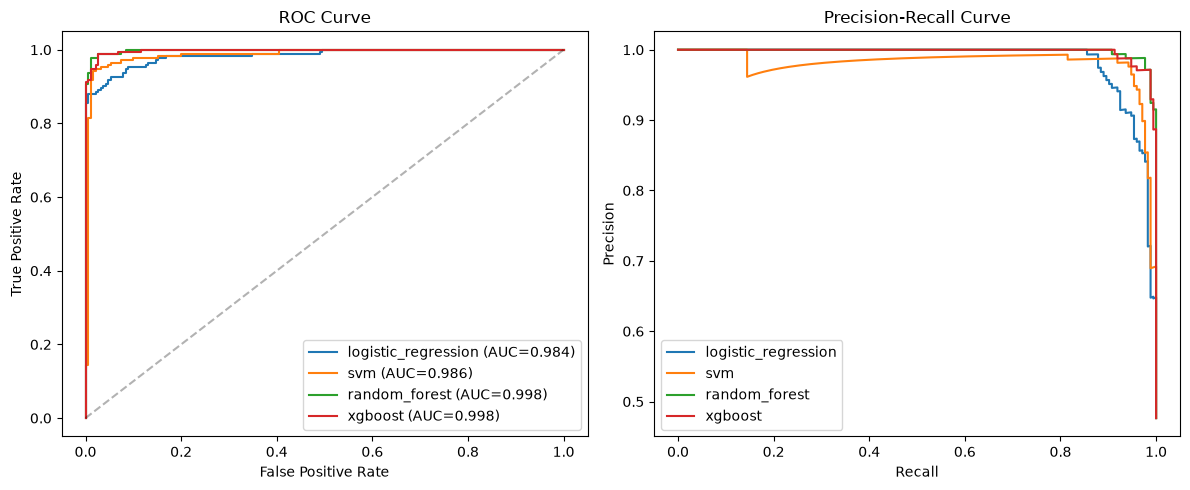

In [364]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, search in fitted_models.items():
    y_proba = search.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_proba):.3f})")

    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    axes[1].plot(rec, prec, label=name)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

### Breakdown by pair type

Each `type` group has a single ground-truth label, so "accuracy within the group" is exactly recall for the positive groups (hard/normal/code-changed positive) and exactly specificity for the negative groups (hard/normal negative). This shows whether a model's good overall F1 is coming from the easy cases or whether it actually holds up on the hard ones.

In [365]:
type_rows = []
for name, search in fitted_models.items():
    y_pred = search.predict(X_test)
    correct = pd.Series(y_pred == y_test.values, index=test_features.index)
    type_rows.append(correct.groupby(test_features["type"]).mean().rename(name))

type_breakdown = pd.concat(type_rows, axis=1)
type_breakdown["n_pairs"] = test_features["type"].value_counts()
display(type_breakdown)

/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,logistic_regression,svm,random_forest,xgboost,n_pairs
type,,,,,
code changed positive,0.750000,0.900000,1.000000,1.000000,20
hard negative,0.906667,0.973333,0.986667,0.986667,75
hard positive,0.946667,0.893333,0.920000,0.973333,75
heliport negative,0.975000,1.000000,0.975000,0.900000,40
heliport positive,1.000000,1.000000,1.000000,1.000000,3
normal negative,0.973333,0.986667,1.000000,1.000000,75
normal positive,0.946667,0.946667,1.000000,1.000000,75


### Error Analysis

Not just the error counts - looking at the actual mis-classified pairs to find patterns

#### False Positives and False Negatives

In [366]:
error_table = test_features[["id1", "id2", "type", "label"]].copy()
for name, search in fitted_models.items():
    error_table[f"pred_{name}"] = search.predict(X_test)

summary_rows = []
for name in fitted_models:
    pred = error_table[f"pred_{name}"]
    fp = ((pred == 1) & (error_table["label"] == 0)).sum()
    fn = ((pred == 0) & (error_table["label"] == 1)).sum()
    summary_rows.append({"model": name, "false_positives": fp, "false_negatives": fn})

display(pd.DataFrame(summary_rows).set_index("model"))

print("\nfalse negatives by type (which kind of positive gets missed):")
for name in fitted_models:
    pred = error_table[f"pred_{name}"]
    fn_mask = (pred == 0) & (error_table["label"] == 1)
    print(f"  {name}:")
    print(error_table.loc[fn_mask, "type"].value_counts().to_string())

print("\nfalse positives by type (which kind of negative gets flagged as a match):")
for name in fitted_models:
    pred = error_table[f"pred_{name}"]
    fp_mask = (pred == 1) & (error_table["label"] == 0)
    print(f"  {name}:")
    print(error_table.loc[fp_mask, "type"].value_counts().to_string())

/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,false_positives,false_negatives
model,,
logistic_regression,10,13
svm,3,14
random_forest,2,6
xgboost,5,2



false negatives by type (which kind of positive gets missed):
  logistic_regression:
type
code changed positive    5
hard positive            4
normal positive          4
  svm:
type
hard positive            8
normal positive          4
code changed positive    2
  random_forest:
type
hard positive    6
  xgboost:
type
hard positive    2

false positives by type (which kind of negative gets flagged as a match):
  logistic_regression:
type
hard negative        7
normal negative      2
heliport negative    1
  svm:
type
hard negative      2
normal negative    1
  random_forest:
type
hard negative        1
heliport negative    1
  xgboost:
type
heliport negative    4
hard negative        1


##### Inspect the pairs side by side

`show_pair_details` prints every column `df_wd` and `df_oa` have in common (`name`, `iata`, `icao`, `lat`, `lon`, `elevation`, `countryName`, `city`, `localCode`, `countryCode`) side by side for each pair - the raw data, not the derived similarity features - the same kind of view used in `create_gold_standard.ipynb` (`inspect_pairs`), rebuilt here since that helper lives in the other notebook. Defaults to the model with the best test F1 from the metrics table above; change `MODEL_TO_INSPECT` to look at a different one.

In [367]:
SHARED_COLS = [c for c in df_wd.columns if c in df_oa.columns and c != "id"]
print(f"shared columns: {SHARED_COLS}")


def show_pair_details(pairs_df, n=10):
    left = df_wd.set_index("id")[SHARED_COLS].add_suffix("_wd")
    right = df_oa.set_index("id")[SHARED_COLS].add_suffix("_oa")
    view = pairs_df[["id1", "id2", "type"]].join(left, on="id1").join(right, on="id2")
    for _, r in view.head(n).iterrows():
        print(f"({r['id1']} <-> {r['id2']})  type={r['type']}")
        for c in SHARED_COLS:
            print(f"  {c:12s} WD: {str(r[c + '_wd']):30s} OA: {r[c + '_oa']}")
        print()


MODEL_TO_INSPECT = results.index[0]  # best model by test F1 (dynamic, see the metrics table above)
pred = error_table[f"pred_{MODEL_TO_INSPECT}"]

print(f"=== {MODEL_TO_INSPECT}: false positives (predicted match, gold says no) ===\n")
show_pair_details(error_table[(pred == 1) & (error_table["label"] == 0)])

print(f"=== {MODEL_TO_INSPECT}: false negatives (predicted non-match, gold says yes) ===\n")
show_pair_details(error_table[(pred == 0) & (error_table["label"] == 1)])

shared columns: ['name', 'iata', 'icao', 'lat', 'lon', 'elevation', 'countryName', 'city', 'localCode', 'countryCode']
=== xgboost: false positives (predicted match, gold says no) ===

(wd_4082 <-> oa_49715)  type=hard negative
  name         WD: leaf cay airport               OA: staniel cay airport
  iata         WD: nan                            OA: TYM
  icao         WD: MYXD                           OA: MYES
  lat          WD: 24.14570498666                 OA: 24.1691
  lon          WD: -76.45860014154                OA: -76.439102
  elevation    WD: 2.0                            OA: 1.524
  countryName  WD: the bahamas                    OA: bahamas
  city         WD: the bahamas                    OA: staniel cay
  localCode    WD: nan                            OA: nan
  countryCode  WD: BS                             OA: BS

(wd_2385 <-> oa_33732)  type=heliport negative
  name         WD: foggia gino lisa airport       OA: alidaunia foggia heliport
  iata         WD: FOG 

##### Findings:

1. **Heliport/aerodrome pairs that sit too close together**: `wd_24154` (Waiheke Island Aerodrome) and `oa_51572` (Onetangi Heliport) are only 1.4 km apart but are two different facilities on the same island - different name, different ICAO (`NZKE` vs. `NZOW`). `distance_km` alone reads "1.4 km" as close enough to be the same airport, and that signal outweighs the dissimilar name/ICAO, producing a false positive. We need to give the model `type` information so it can learn that heliports need a tighter distance match than regular airports - OA has a `type` column, WD does not, so this has to be a one-sided feature (`is_heliport_oa`, added in the before/after ablation below).

2. **Missing values default to 0.0**: by default, a comparator returns `0.0` when either side is missing the compared column - the same score a genuine mismatch would get. That conflates "we don't know" with "truly dissimilar." For example, `zhaosu airport`/`zhaosu tianma airport` has a missing OA `elevation`, which gets scored as if the elevations were completely different, even though the pair shares the token `"zhaosu"` and sits at a plausible distance - a case we'd otherwise expect to classify correctly. We add `NeutralOnMissingComparator` (neutral `0.5` instead of `0.0`) plus a `MissingFlagComparator` for the columns that are frequently missing (`city`, `countryName`, `countryCode`, `localCode`, `elevation`), added in the before/after ablation below.

#### Before/After: Missing-Value Handling & Heliport Flag

Sections 2-4 deliberately use a **baseline** feature set: plain comparators for `city`/`countryName`/`countryCode`/`localCode`/`elevation` (missing -> 0.0, no flag column) and no `is_heliport_oa` flag for `lat`/`lon`. Now that error analysis above has identified two gaps, we add them on top of that baseline to build an **after** feature set:

1. The `NeutralOnMissingComparator`/`MissingFlagComparator` pattern (missing values score as neutral 0.5 instead of a maximally-dissimilar 0.0, with a separate flag column) for `city`, `countryName`, `countryCode`, `localCode`, `elevation`.
2. The `is_heliport_oa` flag for `lat`/`lon` (OA-side only -- WD has no `type` column).

We retrain the same four model architectures on this after feature set, then compare the single best model from Section 3/4 (`results`, the baseline) against the single best model trained here on the after features.


In [368]:
class NeutralOnMissingComparator(BaseComparator):
    """Wraps a comparator so a missing value on either side returns a neutral score
    instead of the wrapped comparator's default of 0.0 (= maximally dissimilar).
    This re-write the return values of comparators, which default is 0.0. 
    """

    def __init__(self, inner, column, neutral=0.5):
        super().__init__(name=f"NeutralOnMissing({inner.name})")
        self.inner = inner
        self.column = column
        self.neutral = neutral

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if pd.isna(v1) or pd.isna(v2):
            return self.neutral
        return self.inner.compare(record1, record2)


class MissingFlagComparator(BaseComparator):
    """1.0 if either side is missing this column, else 0.0.
    It will create new columns (features), showing the features has missing value or not. 
    """

    def __init__(self, column):
        super().__init__(name=f"MissingFlagComparator({column})")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        return 1.0 if (pd.isna(v1) or pd.isna(v2)) else 0.0

In [369]:
class HeliportFlagComparator(BaseComparator):
    """1.0 if the OA-side record's `type` is "heliport", else 0.0. WD has no `type`
    column, so this is a one-sided signal (not a two-sided comparison) - lets tree models
    learn that heliports need a tighter distance_km match than regular airports."""

    def __init__(self, type_column="type"):
        super().__init__(name="is_heliport_oa")
        self.type_column = type_column

    def compare(self, record1, record2):
        return 1.0 if record2.get(self.type_column) == "heliport" else 0.0


#### Why NeutralOnMissingComparator (return 0.5 instead of 0.0 on missing):

By default, a comparator returns 0.0 when either side's value is missing — identical to a genuine "completely dissimilar" score. This causes two problems: it conflates "no data" with "truly dissimilar," and when fed through StandardScaler (for Logistic Regression/SVM), these artificial 0.0s skew the column's mean/std for every row, not just the missing ones. Replacing it with a neutral 0.5 avoids both issues.

#### Why that alone isn't enough — need MissingFlagComparator too:

Setting missing values to 0.5 just moves the problem: now a missing pair and a pair that genuinely scores 0.5 similarity look identical to the model — one number can't represent two different situations. Whatever constant you pick to represent "unknown," it will always collide with real cases that happen to score the same value.

The fix is a separate flag column (1 if missing, 0 otherwise). It doesn't force any particular correction — the model learns from the training data whether missing-ness correlates with matches being more or less likely (it could go either way, or not matter at all, in which case its weight just stays near zero).

In [370]:
MISSING_VALUE_COLUMNS = {
    "city": city_comparators,
    "countryName": countryname_comparators,
    "countryCode": countrycode_comparators,
    "localCode": localcode_comparators,
    "elevation": elevation_comparators,
}


def add_missing_handling(raw_comparators, column):
    """Wrap each raw comparator with NeutralOnMissingComparator (missing -> neutral 0.5)
    and append a MissingFlagComparator for that column."""
    wrapped = [NeutralOnMissingComparator(c, column=column) for c in raw_comparators]
    wrapped.append(MissingFlagComparator(column=column))
    return wrapped


after_comparators = list(name_comparators)
for column, raw in MISSING_VALUE_COLUMNS.items():
    after_comparators += add_missing_handling(raw, column)
after_comparators += geo_comparators + [HeliportFlagComparator()]

print(f"baseline (before) feature comparators: {len(comparators)}")
print(f"after             feature comparators: {len(after_comparators)}")


baseline (before) feature comparators: 26
after             feature comparators: 32


In [371]:
after_extractor = FeatureExtractor(after_comparators)
AFTER_FEATURE_COLS = after_extractor.get_feature_names()

after_train_val_features = after_extractor.create_features(
    df_wd, df_oa, train_val_r[["id1", "id2"]], id_column="id", labels=train_val_r["label"]
)
after_test_features = after_extractor.create_features(
    df_wd, df_oa, test_r[["id1", "id2"]], id_column="id", labels=test_r["label"]
)

X_after_train_val = after_train_val_features[AFTER_FEATURE_COLS]
y_after_train_val = after_train_val_features["label"]
X_after_test = after_test_features[AFTER_FEATURE_COLS]
y_after_test = after_test_features["label"]

print(f"after train_val feature matrix: {X_after_train_val.shape}")
print(f"after test feature matrix:      {X_after_test.shape}")


after train_val feature matrix: (847, 32)
after test feature matrix:      (363, 32)


Train the same four model architectures (same pipelines, hyperparameter grids, and CV folds as Section 3) on the after feature set. The grids are re-declared here -- rather than reused from Section 3's cells, which only kept them inline inside each `fit_model` call -- so this ablation can run as a self-contained rerun.


In [372]:
MODEL_SPECS = {
    "logistic_regression": (
        Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "svm": (
        Pipeline([("scaler", StandardScaler()), ("clf", SVC(probability=True, random_state=SEED))]),
        {"clf__C": [0.1, 1.0, 10.0], "clf__kernel": ["rbf", "linear"]},
    ),
    "random_forest": (
        Pipeline([("clf", RandomForestClassifier(random_state=SEED))]),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 10, 20]},
    ),
    "xgboost": (
        Pipeline([("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1))]),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 6], "clf__learning_rate": [0.05, 0.1]},
    ),
}

after_fitted_models = {}
for name, (pipeline, param_grid) in MODEL_SPECS.items():
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1", n_jobs=1)
    search.fit(X_after_train_val, y_after_train_val)
    after_fitted_models[name] = search
    print(f"{name:<22} best CV F1 = {search.best_score_:.3f}  best params = {search.best_params_}")


logistic_regression    best CV F1 = 0.945  best params = {'clf__C': 1.0}


/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/

svm                    best CV F1 = 0.952  best params = {'clf__C': 10.0, 'clf__kernel': 'rbf'}
random_forest          best CV F1 = 0.974  best params = {'clf__max_depth': None, 'clf__n_estimators': 300}
xgboost                best CV F1 = 0.978  best params = {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 300}


In [373]:
after_rows = []
for name, search in after_fitted_models.items():
    y_pred = search.predict(X_after_test)
    y_proba = search.predict_proba(X_after_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_after_test, y_pred).ravel()
    after_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_after_test, y_pred),
        "precision": precision_score(y_after_test, y_pred),
        "recall": recall_score(y_after_test, y_pred),
        "f1": f1_score(y_after_test, y_pred),
        "roc_auc": roc_auc_score(y_after_test, y_proba),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    })

after_results = pd.DataFrame(after_rows).set_index("model").sort_values("f1", ascending=False)
display(after_results)

best_after_name = after_results.index[0]
print(f"\nbest after model: {best_after_name}")
display(after_results.loc[[best_after_name]])


/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/borya/Documents/Mannheim Documents/First Semester/Web Data Integration/Projects/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/borya/Do

,accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
model,,,,,,,,,
random_forest,0.983471,0.994083,0.971098,0.982456,0.999103,168,1,5,189
xgboost,0.980716,0.988235,0.971098,0.979592,0.998479,168,2,5,188
svm,0.961433,0.959538,0.959538,0.959538,0.989322,166,7,7,183
logistic_regression,0.942149,0.931818,0.947977,0.939828,0.990173,164,12,9,178



best after model: random_forest


,accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
model,,,,,,,,,
random_forest,0.983471,0.994083,0.971098,0.982456,0.999103,168,1,5,189


##### Best Model Comparison: Before vs. After

Compares the single best baseline model (Section 3/4's `results`) against the single best model trained here on the after features -- these can be different architectures, since the point is "what's the best model I'd ship before this feature work" vs "...after", not matching architectures one-to-one.


In [374]:
best_before_name = results.index[0]

METRIC_COLS = ["accuracy", "precision", "recall", "f1", "roc_auc", "tp", "fp", "fn", "tn"]
best_comparison = pd.DataFrame({
    "before": results.loc[best_before_name, METRIC_COLS],
    "after": after_results.loc[best_after_name, METRIC_COLS],
})
best_comparison["delta"] = best_comparison["after"] - best_comparison["before"]

print(f"before: {best_before_name}")
print(f"after:  {best_after_name}")
display(best_comparison)


before: xgboost
after:  random_forest


,before,after,delta
accuracy,0.980716,0.983471,0.002755
precision,0.971591,0.994083,0.022492
recall,0.988439,0.971098,-0.017341
f1,0.979943,0.982456,0.002513
roc_auc,0.997597,0.999103,0.001506
tp,171.000000,168.000000,-3.000000
fp,5.000000,1.000000,-4.000000
fn,2.000000,5.000000,3.000000
tn,185.000000,189.000000,4.000000


Since the model after adding new features performs slightly better than the original model, it is chosen as the final model.


## Feature Importance

Feature importance for the model actually used to score candidates in the Apply step below - the best model from the before/after ablation's `after_results` (Section 5), since that's the one we decided to ship. Tree models (Random Forest, XGBoost) expose `feature_importances_` (mean decrease in impurity); Logistic Regression and a linear-kernel SVM expose `coef_` (on the standardized feature scale, so magnitudes are directly comparable within that model). If the best model turns out to be an SVM with a non-linear kernel, neither is available.


distance_km                                                                                0.248207
NeutralOnMissing(NumericComparator(elevation, absolute_difference, list_strategy=None))    0.086785
NeutralOnMissing(NumericComparator(elevation, relative_difference, list_strategy=None))    0.066012
MongeElkanComparator(name)                                                                 0.057683
ContainmentComparator(name)                                                                0.056024
ExtendedJaccardComparator(name)                                                            0.047827
StringComparator(name, levenshtein, tokenization=char, list_strategy=None)                 0.040716
StringComparator(name, overlap, tokenization=word, list_strategy=None)                     0.040189
NeutralOnMissing(ExactMatchComparator(localCode))                                          0.039691
PhoneticOverlapComparator(name, soundex)                                                   0.038168


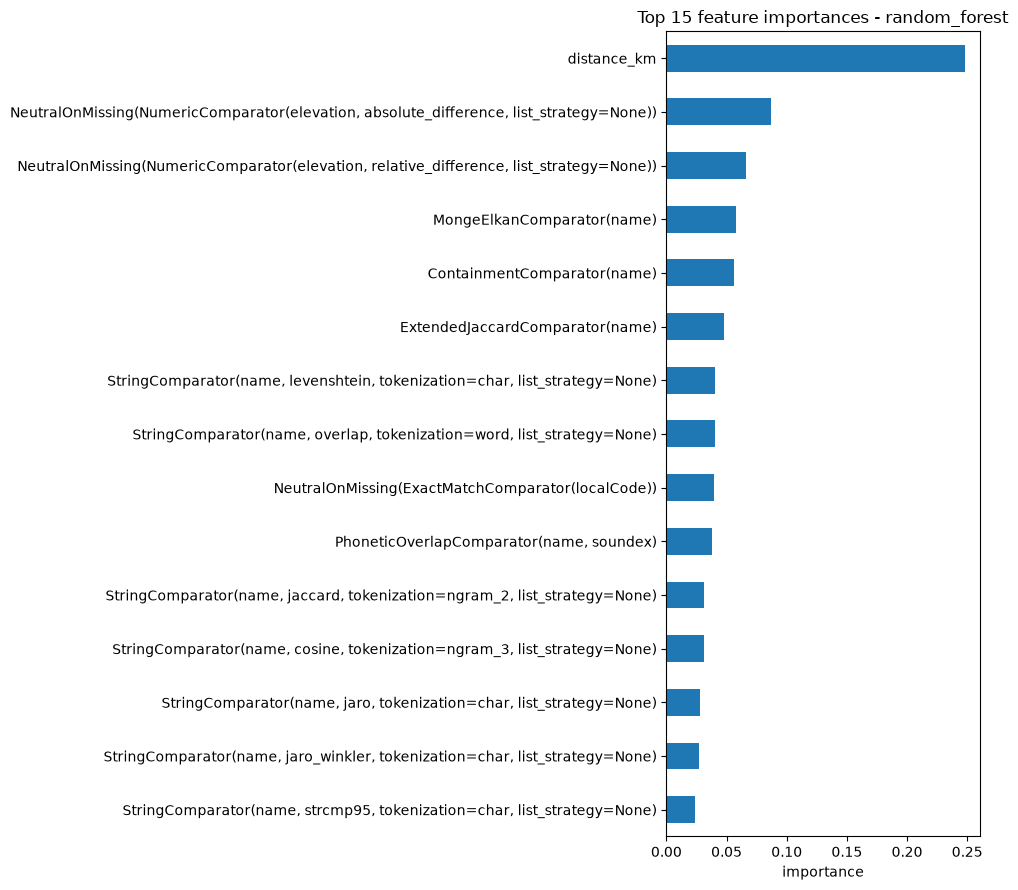

In [387]:
BEST_MODEL_NAME = best_after_name
best_model = after_fitted_models[BEST_MODEL_NAME]
clf = best_model.best_estimator_.named_steps["clf"]

if hasattr(clf, "feature_importances_"):
    importances = pd.Series(clf.feature_importances_, index=AFTER_FEATURE_COLS, name="importance")
elif hasattr(clf, "coef_"):
    importances = pd.Series(clf.coef_[0], index=AFTER_FEATURE_COLS, name="coefficient")
else:
    raise ValueError(
        f"{type(clf).__name__} exposes neither feature_importances_ nor coef_ "
        f"(e.g. an SVM with a non-linear kernel) - feature importance isn't available for this model"
    )

importances = importances.reindex(importances.abs().sort_values(ascending=False).index)
display(importances.head(15))

fig, ax = plt.subplots(figsize=(10, 9))
importances.head(15).iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel(importances.name)
ax.set_title(f"Top 15 feature importances - {BEST_MODEL_NAME}")
plt.tight_layout()
plt.show()


## 7. Apply the Matcher

Block the full Wikidata x OurAirports datasets and score every candidate pair with the best-performing model. Conflicting candidates (the same record matched more than once) are not resolved into a one-to-one set here - see the Cluster Analysis section below, which tags and saves them instead. First step: blocking, reusing the exact Rule A (`countryCode` + distinguishing `name` token) and Rule B (H3 geographic grid) from `create_gold_standard.ipynb`, so the candidate pool the matcher sees is built the same way the gold standard's negatives were.


### Blocking

Two blocking rules, concatenated:
- **Rule A**: `countryCode` + distinguishing `name` token.
- **Rule B**: geographic grid (H3).

#### Rule A

`TokenBlocker` on `name`, with `countryCode` prepended to each token (so a pair is a candidate only if the two records share a distinguishing token **and** have the same country). Tokens that would each create more than `MAX_PAIRS_PER_TOKEN` candidate pairs are excluded first (derived from the data, not hand-picked) - identical method to `create_gold_standard.ipynb`.

In [376]:
from collections import Counter

from PyDI.entitymatching import TokenBlocker

MAX_PAIRS_PER_TOKEN = 2000  # trade-off between block size and recall; tune with the debug CSV


def name_tokens(name):
    if not isinstance(name, str):
        return set()
    return {t for t in name.split() if len(t) >= 2}


doc_freq_wd = Counter(t for n in df_wd["name"] for t in name_tokens(n))
doc_freq_oa = Counter(t for n in df_oa["name"] for t in name_tokens(n))

COMMON_TOKENS = {
    t for t, c in doc_freq_wd.items()
    if c * doc_freq_oa.get(t, 0) > MAX_PAIRS_PER_TOKEN
}
print(f"Excluding {len(COMMON_TOKENS)} tokens that would each create more than "
      f"{MAX_PAIRS_PER_TOKEN} candidate pairs")


# The tokenizer only sees one column, so country and name are packed into one string.
def add_name_with_country(d):
    d = d.copy()
    d["name_with_country"] = d["countryCode"].fillna("") + "|" + d["name"].fillna("")
    return d


wd_blk = add_name_with_country(df_wd)
oa_blk = add_name_with_country(df_oa)


def country_scoped_tokenizer(text):
    if not isinstance(text, str) or "|" not in text:
        return []
    country, name = text.split("|", 1)
    if not country:          # Rule A needs a country code
        return []
    return [f"{country}_{t}" for t in name.split()
            if len(t) >= 2 and t not in COMMON_TOKENS]


blocker_token = TokenBlocker(
    df_left=wd_blk,
    df_right=oa_blk,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Rule A candidate pairs: {len(candidates_token):,} "
      f"(estimated before materializing: {blocker_token.estimate_pairs():,})")

Excluding 131 tokens that would each create more than 2000 candidate pairs
Rule A candidate pairs: 198,724 (estimated before materializing: 206,951)


#### Rule B

Map each record to an H3 hexagonal cell (resolution `RESOLUTION`) and `TokenBlocker` the cell id plus its 6 neighbors (7 tokens per record), so two records in the same or adjacent cells always share a token. No `countryCode` requirement, and no `countryCode` in the token - identical method to `create_gold_standard.ipynb`.

In [377]:
import h3

RESOLUTION = 9


def geo_h3_tokens(row):
    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        return []
    center = h3.latlng_to_cell(row["lat"], row["lon"], RESOLUTION)
    return list(h3.grid_disk(center, 1))


wd_geo = df_wd.copy()
oa_geo = df_oa.copy()

wd_geo["geo_grid_tokens"] = wd_geo.apply(geo_h3_tokens, axis=1)
oa_geo["geo_grid_tokens"] = oa_geo.apply(geo_h3_tokens, axis=1)

# one lookup for both sources (ids are prefixed, so they cannot collide)
grid_token_lookup = {
    **wd_geo.set_index("id")["geo_grid_tokens"].to_dict(),
    **oa_geo.set_index("id")["geo_grid_tokens"].to_dict(),
}


def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])


# TokenBlocker only sees one column, so the id itself is the "text" to tokenize
wd_geo["id_as_text"] = wd_geo["id"]
oa_geo["id_as_text"] = oa_geo["id"]

blocker_geo = TokenBlocker(
    df_left=wd_geo,
    df_right=oa_geo,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
    min_token_len=1,
)

candidates_geo = blocker_geo.materialize()
print(f"Rule B candidate pairs: {len(candidates_geo):,}")

Rule B candidate pairs: 22,123


#### Concatenate and Deduplicate

In [378]:
candidates = pd.concat([candidates_geo[["id1", "id2"]], candidates_token[["id1", "id2"]]], axis=0)
candidates = candidates.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"All candidate pairs after deduplication: {len(candidates):,}")

All candidate pairs after deduplication: 201,295


#### Ground-Truth Positives for Blocking Recall

The gold standard's 568 sampled positives are a biased, small sample (half of them deliberately picked as the *hardest* cases). To get a recall estimate with real statistical power and that reflects what blocking will actually face at full scale, build the ground-truth positives directly from the full data instead, the same two ways `create_gold_standard.ipynb` found positives in the first place:

1. **ICAO merge**: valid ICAO present and equal on both sides.
2. **ICAO differs, IATA matches**: valid IATA present and equal on both sides, ICAO differs, within 50 km (same rule as the code-changed positives).

The two are disjoint by construction (one requires equal ICAO, the other requires differing ICAO) and are combined by union.

In [379]:
valid_icao = r"^[A-Z0-9]{4}$"
valid_iata = r"^[A-Z]{3}$"

# 1. ICAO merge
wd_icao = df_wd[df_wd["icao"].astype(str).str.match(valid_icao, na=False)]
oa_icao = df_oa[df_oa["icao"].astype(str).str.match(valid_icao, na=False)]
icao_pairs = pd.merge(wd_icao, oa_icao, on="icao", how="inner", suffixes=("_wd", "_oa"))
print(f"dataset 1 (ICAO merge): {len(icao_pairs):,} pairs")

# 2. ICAO differs, IATA matches, within 50 km
wd_iata = df_wd[df_wd["iata"].astype(str).str.match(valid_iata, na=False)]
oa_iata = df_oa[df_oa["iata"].astype(str).str.match(valid_iata, na=False)]
iata_pairs = pd.merge(wd_iata, oa_iata, on="iata", how="inner", suffixes=("_wd", "_oa"))

iata_pairs["dist_km"] = [
    haversine_km(a, b, c, d)
    for a, b, c, d in zip(iata_pairs["lat_wd"], iata_pairs["lon_wd"],
                          iata_pairs["lat_oa"], iata_pairs["lon_oa"])
]
icao_differs = iata_pairs["icao_wd"] != iata_pairs["icao_oa"]
code_changed_pairs = iata_pairs[icao_differs & (iata_pairs["dist_km"].fillna(999) <= 50)]
print(f"dataset 2 (ICAO differs, IATA matches, <=50km): {len(code_changed_pairs):,} pairs")

# combine
ground_truth_positives = (
    set(icao_pairs[["id_wd", "id_oa"]].itertuples(index=False, name=None))
    | set(code_changed_pairs[["id_wd", "id_oa"]].itertuples(index=False, name=None))
)
print(f"combined ground-truth positives: {len(ground_truth_positives):,} pairs")

dataset 1 (ICAO merge): 7,758 pairs
dataset 2 (ICAO differs, IATA matches, <=50km): 724 pairs
combined ground-truth positives: 8,482 pairs


### Blocking Key Validation: Recall & Reduction Ratio

Measure the blocking step (Rule A or Rule B, deduplicated) against `ground_truth_positives` (built above):

- **Recall (Pair Completeness)**: for each ground-truth positive pair, check whether that exact `(id1, id2)` pair ended up in `candidates`. Recall is the fraction that did.
- **Reduction Ratio** = `1 - (candidate pairs) / (|WD| x |OA|)`.

Target from the Methods above: recall > 97%.

In [380]:
found_pairs = set(candidates[["id1", "id2"]].itertuples(index=False, name=None))
hits = sum(1 for p in ground_truth_positives if p in found_pairs)
recall_pc = hits / len(ground_truth_positives)

total_possible_pairs = len(df_wd) * len(df_oa)
reduction_ratio = 1 - len(candidates) / total_possible_pairs

print(f"candidate pairs: {len(candidates):,}")
print(f"recall (pair completeness): {recall_pc:.4f}  ({hits:,}/{len(ground_truth_positives):,})")
print(f"reduction ratio: {reduction_ratio:.6f}")
print(f"recall > 97%: {recall_pc > 0.97}")

candidate pairs: 201,295
recall (pair completeness): 0.9841  (8,347/8,482)
reduction ratio: 0.999906
recall > 97%: True


### Extract Features for All Candidates

Reuse the same `after_extractor` (the after-ablation feature set from Section 5 - the baseline comparators plus missing-value handling and `is_heliport_oa`, since that's the feature set the model we're shipping was trained on) on the full blocked `candidates` set - no labels this time, since these are unlabeled real-world pairs, not gold-standard pairs. Same consistency reasoning as before: the exact feature-computation code used for training must be used here, or the model is scoring something different from what it learned on.


In [381]:
candidate_features = after_extractor.create_features(
    df_wd, df_oa, candidates[["id1", "id2"]], id_column="id"
)

print(f"candidate feature matrix: {candidate_features.shape}")
display(candidate_features.head(3))


candidate feature matrix: (201295, 34)


,id1,id2,"StringComparator(name, levenshtein, tokenization=char, list_strategy=None)","StringComparator(name, jaro, tokenization=char, list_strategy=None)","StringComparator(name, jaro_winkler, tokenization=char, list_strategy=None)","StringComparator(name, strcmp95, tokenization=char, list_strategy=None)","StringComparator(name, jaccard, tokenization=word, list_strategy=None)","StringComparator(name, sorensen_dice, tokenization=word, list_strategy=None)","StringComparator(name, overlap, tokenization=word, list_strategy=None)","StringComparator(name, cosine, tokenization=word, list_strategy=None)",...,MissingFlagComparator(countryCode),"NeutralOnMissing(StringComparator(localCode, levenshtein, tokenization=char, list_strategy=None))",NeutralOnMissing(ExactMatchComparator(localCode)),MissingFlagComparator(localCode),"NeutralOnMissing(NumericComparator(elevation, absolute_difference, list_strategy=None))","NeutralOnMissing(NumericComparator(elevation, relative_difference, list_strategy=None))",MissingFlagComparator(elevation),distance_km,coordinate_missing,is_heliport_oa
0,wd_1,oa_19599,0.8,0.85,0.88,0.88,0.666667,0.8,1.0,0.816497,...,0.0,0.5,0.5,1.0,0.996488,0.991833,0.0,0.070360,0.0,0.0
1,wd_2,oa_85742,1.0,1.00,1.00,1.00,1.000000,1.0,1.0,1.000000,...,0.0,0.5,0.5,1.0,0.500000,0.500000,1.0,0.000088,0.0,0.0
2,wd_3,oa_85933,1.0,1.00,1.00,1.00,1.000000,1.0,1.0,1.000000,...,0.0,0.5,0.5,1.0,0.500000,0.500000,1.0,0.000054,0.0,0.0


### Score with the Best Model

Pick the model with the best test F1 from the `after_results` metrics table (the before/after ablation in Section 5), rather than hard-coding a name, since that table is the thing that actually decides "best" among the models trained on the feature set we're shipping. Score every candidate with `predict_proba`, then keep only pairs at or above the same 0.5 decision threshold used throughout evaluation.


In [382]:
BEST_MODEL_NAME = after_results.index[0]
best_model = after_fitted_models[BEST_MODEL_NAME]
print(f"applying best model: {BEST_MODEL_NAME}")

MATCH_THRESHOLD = 0.5  # for models to decide match or non-match

# this is the threshold the professor mentions in local matching / global matching

X_candidates = candidate_features[AFTER_FEATURE_COLS]
candidate_features["score"] = best_model.predict_proba(X_candidates)[:, 1]

above_threshold = candidate_features[candidate_features["score"] >= MATCH_THRESHOLD][["id1", "id2", "score"]]
print(f"{len(above_threshold):,} / {len(candidate_features):,} candidate pairs score >= {MATCH_THRESHOLD}")


applying best model: random_forest
24,553 / 201,295 candidate pairs score >= 0.5


## Cluster Analysis

Group the above-threshold pairs into connected components (plain union-find, not PyDI's `ConnectedComponentClusterer` - that one outputs *all pairwise combinations* within a cluster, including, e.g., an OA-OA pair inside a 3-node cluster, which has no meaning in our WD-vs-OA setup). Each pair keeps its own `score`; `cluster` just tags which component it belongs to, so a cluster with more than 2 members (a conflict - the same WD or OA record matched to more than one record on the other side) is visible directly in the saved output rather than being silently resolved away.


In [383]:
def find_clusters(pairs_df):
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            x = parent[x]
        return x

    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry:
            parent[rx] = ry

    for _, row in pairs_df.iterrows():
        union(row["id1"], row["id2"])

    groups = {}
    for node in parent:
        groups.setdefault(find(node), set()).add(node)
    return list(groups.values())


clusters = find_clusters(above_threshold)
cluster_sizes = pd.Series([len(c) for c in clusters])

print(f"{len(clusters):,} connected components from {len(above_threshold):,} above-threshold pairs")
print("\ncluster size frequency:")
print(cluster_sizes.value_counts().sort_index())

id_to_cluster = {node: i for i, cluster in enumerate(clusters) for node in cluster}

final_correspondences = above_threshold.copy()
final_correspondences["cluster"] = final_correspondences["id1"].map(id_to_cluster)
final_correspondences = final_correspondences.rename(columns={"id1": "id_1", "id2": "id_2"})
final_correspondences = final_correspondences[["id_1", "id_2", "score", "cluster"]]

print(f"\n{len(final_correspondences):,} correspondences, tagged with their cluster id")
display(final_correspondences.head(3))


22,716 connected components from 24,553 above-threshold pairs

cluster size frequency:
2     21537
3       906
4       207
5        35
6        10
7         5
8         5
9         2
10        2
12        1
15        1
21        1
22        1
28        1
32        1
63        1
Name: count, dtype: int64

24,553 correspondences, tagged with their cluster id


,id_1,id_2,score,cluster
0,wd_1,oa_19599,0.976667,0
1,wd_2,oa_85742,0.963333,1
2,wd_3,oa_85933,0.956667,2


In [384]:
import numpy as np

multi_clusters = [c for c in clusters if len(c) > 2]
print(f"{len(multi_clusters):,} / {len(clusters):,} clusters have more than 2 members")

coords = pd.concat([
    df_wd.set_index("id")[["lat", "lon"]],
    df_oa.set_index("id")[["lat", "lon"]],
])


def cluster_max_distance_km(node_ids):
    pts = coords.loc[coords.index.intersection(node_ids)].dropna()[["lat", "lon"]].values
    if len(pts) < 2:
        return np.nan
    max_dist = 0.0
    for i in range(len(pts)):
        for j in range(i + 1, len(pts)):
            max_dist = max(max_dist, haversine_km(pts[i][0], pts[i][1], pts[j][0], pts[j][1]))
    return max_dist


cluster_max_dist = pd.Series([cluster_max_distance_km(c) for c in multi_clusters])

print("\nmax pairwise distance within each >2-member cluster:")
display(cluster_max_dist.describe())

distance_buckets = pd.cut(
    cluster_max_dist,
    bins=[-0.001, 5, 50, float("inf")],
    labels=["tight (<=5km)", "mid (5-50km)", "far (>50km)"],
)
print("\nbucketed:")
print(distance_buckets.value_counts().sort_index())


1,179 / 22,716 clusters have more than 2 members

max pairwise distance within each >2-member cluster:


count    1179.000000
mean      176.788165
std       697.037179
min         0.000113
25%         0.576373
50%         1.379177
75%         7.208705
max      7191.753128
dtype: float64


bucketed:
tight (<=5km)    837
mid (5-50km)     197
far (>50km)      145
Name: count, dtype: int64


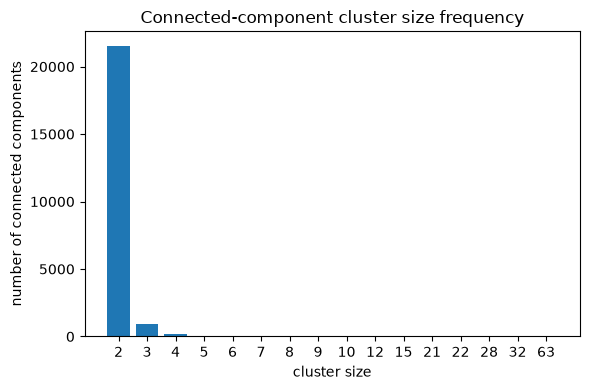

In [385]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cluster_sizes.value_counts().sort_index().index.astype(str),
       cluster_sizes.value_counts().sort_index().values)
ax.set_xlabel("cluster size")
ax.set_ylabel("number of connected components")
ax.set_title("Connected-component cluster size frequency")
plt.tight_layout()
plt.show()


1,179 of the 22,716 clusters have more than 2 members - i.e. the same WD or OA record matched to more than one record on the other side. Bucketing each cluster's maximum pairwise distance between its members shows these conflicts are not one uniform problem:

- **tight (<=5km), 837 clusters (71%)**: mostly genuine duplicate records *within* one source for the same real airport - e.g. OA carrying both `sturgis municipal airport` and `old sturgis airport`, or a current/duplicate-flagged pair like `oa_17981` literally named `"duplicateyeg"` next to `edmonton international airport`. Not a matcher error.
- **far (>50km), 145 clusters (12%)**: almost entirely matcher false positives, usually a shared generic name token linking genuinely different airports 
    -  four distinct Chongqing-area airports chained together through `"chongqing"` + `"airport"`
    - `wd_5192` (`curtiss southwest field`, all core fields including lat/lon missing) matched to 24 unrelated `"southwest ___ airport"` OA records across the US purely because `distance_km` falls back to a constant when coordinates are missing.
- **mid (5-50km), 197 clusters (17%)**: ambiguous - a mix of the noisy-coordinate same-airport pattern from error analysis and genuine false positives.


### Save the Final Correspondences

Save `final_correspondences` (`id_1`, `id_2`, `score`, `cluster`) from the cluster analysis above.


In [386]:
APPLY_OUTPUT_DIR = Path("../../../data/identity_resolution/outputs")
APPLY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = APPLY_OUTPUT_DIR / "wd_oa_correspondences.csv"
final_correspondences.to_csv(output_path, index=False)
print(f"saved {len(final_correspondences):,} correspondences to {output_path}")

saved 24,553 correspondences to ../../../data/identity_resolution/outputs/wd_oa_correspondences.csv
